# Demo de market-toolkit, paso a paso

Recorre la ingesta de datos, el análisis de una cartera, una simulación Monte Carlo y la generación de informes. Ejecuta las celdas en orden desde la raíz del repositorio. Los resultados se guardan en `outputs/`.


## 0. Configuración e imports

Elige si descargar datos reales o usar datos sintéticos. En modo real, si la descarga falla, el flujo continúa con datos sintéticos. Las claves opcionales de Alpha Vantage y FRED se leen desde la configuración del proyecto.


In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from market_toolkit import config
from market_toolkit.models import FinancialSeries, Portfolio, TipoActivo
from market_toolkit.simulation import MonteCarlo

# Cambia a False para ejecutar sin conexión con datos sintéticos.
USAR_DATOS_REALES = True

CARPETA_SALIDA = Path("outputs")
ACCIONES = ["AAPL", "MSFT", "JPM"]
INDICE = "^GSPC"
INICIO = "2022-01-01"
FIN = "2024-12-31"
PESOS = {"AAPL": 0.35, "MSFT": 0.35, "JPM": 0.30}
TIPO_LIBRE_RIESGO_POR_DEFECTO = 0.04
CARPETA_SALIDA.mkdir(exist_ok=True)


## 1. Ingesta de datos

Se descargan acciones e índice desde Yahoo Finance. Oro y tipo libre de riesgo se añaden cuando están configuradas sus claves. Los datos sintéticos usan la misma estructura `FinancialSeries`.


In [2]:
def descargar_datos_reales():
    from market_toolkit.providers.providers import (
        AlphaVantageProvider,
        MacroProvider,
        YahooFinanceProvider,
    )

    print("Yahoo Finance: acciones e índice...")
    series = YahooFinanceProvider(ACCIONES + [INDICE]).download(inicio=INICIO, fin=FIN)

    if config.ALPHAVANTAGE_API_KEY:
        print("Alpha Vantage: oro...")
        series += AlphaVantageProvider(["ORO"]).download(inicio=INICIO, fin=FIN)
    else:
        print("Alpha Vantage: sin clave configurada, se omite.")

    tipo_libre_riesgo = TIPO_LIBRE_RIESGO_POR_DEFECTO
    if config.FRED_API_KEY:
        print("FRED: letras del Tesoro a 3 meses (DTB3)...")
        letras = MacroProvider(["DTB3"]).download(inicio=INICIO, fin=FIN)[0]
        tipo_libre_riesgo = letras.ultimo_valor / 100
    else:
        print("FRED: sin clave configurada, se usa el tipo libre de riesgo fijo.")
    return series, tipo_libre_riesgo


def generar_datos_sinteticos():
    fechas = pd.bdate_range(INICIO, FIN)
    rng = np.random.default_rng(42)
    series = []
    for ticker in ACCIONES + [INDICE]:
        rendimientos = rng.normal(0.0004, 0.015, len(fechas))
        precios = pd.Series(100 * np.exp(np.cumsum(rendimientos)), index=fechas, name=ticker)
        tipo = TipoActivo.INDICE if ticker == INDICE else TipoActivo.ACCION
        series.append(
            FinancialSeries(
                precios,
                tipo,
                moneda="USD",
                proveedor="Sintético",
                metadatos={"nombre": f"{ticker} (sintético)"},
            )
        )
    return series, TIPO_LIBRE_RIESGO_POR_DEFECTO


if USAR_DATOS_REALES:
    try:
        series, tipo_libre_riesgo = descargar_datos_reales()
    except Exception as error:
        print(f"No se han podido descargar los datos ({type(error).__name__}: {error}).")
        print("Se continúa con datos sintéticos.")
        series, tipo_libre_riesgo = generar_datos_sinteticos()
else:
    series, tipo_libre_riesgo = generar_datos_sinteticos()


Yahoo Finance: acciones e índice...
Alpha Vantage: oro...
FRED: letras del Tesoro a 3 meses (DTB3)...


In [3]:
print("Series obtenidas (todas son FinancialSeries):")
for serie in series:
    resumen_serie = serie.resumen()
    print(
        f"{resumen_serie['activo']:<8} {str(resumen_serie['nombre'])[:28]:<28} "
        f"{resumen_serie['tipo']:<14} {resumen_serie['proveedor']:<14} "
        f"rent. {resumen_serie['rentabilidad_anualizada']:>7.2%}   "
        f"vol. {resumen_serie['volatilidad_anualizada']:>7.2%}"
    )
print(f"Tipo libre de riesgo: {tipo_libre_riesgo:.2%}")


Series obtenidas (todas son FinancialSeries):
MSFT     Microsoft Corporation        acción         Yahoo Finance  rent.  13.49%   vol.  27.59%
AAPL     Apple Inc.                   acción         Yahoo Finance  rent.  16.36%   vol.  27.11%
JPM      JPMorgan Chase & Co.         acción         Yahoo Finance  rent.  21.03%   vol.  25.01%
^GSPC    S&P 500                      índice         Yahoo Finance  rent.   8.89%   vol.  17.51%
GOLD     Oro                          materia prima  Alpha Vantage  rent.   9.44%   vol.  11.96%
Tipo libre de riesgo: 4.23%


## 2. Construcción de la cartera

El índice queda como referencia y la cartera contiene únicamente los activos incluidos en `PESOS`. Los pesos se fijan al inicio y derivan con el rendimiento de los activos, sin rebalanceo.


In [4]:
acciones = [serie for serie in series if serie.activo in PESOS]
pesos = pd.DataFrame(PESOS, index=[pd.Timestamp(INICIO)])
with warnings.catch_warnings():
    warnings.simplefilter("ignore", UserWarning)
    cartera = Portfolio(acciones, pesos)

resumen_cartera = cartera.resumen()
print(f"Periodo: {resumen_cartera['inicio']} a {resumen_cartera['fin']} "
      f"({resumen_cartera['observaciones']} sesiones)")
print(f"Rentabilidad anualizada: {resumen_cartera['rentabilidad_anualizada']:.2%}")
print(f"Volatilidad anualizada:  {resumen_cartera['volatilidad_anualizada']:.2%}")
print("Pesos al inicio y al cierre:")
for activo in PESOS:
    print(f"  {activo:<6} {PESOS[activo]:>7.2%} -> "
          f"{resumen_cartera['pesos_actuales'][activo]:>7.2%}")


Periodo: 2022-01-03 a 2024-12-30 (752 sesiones)
Rentabilidad anualizada: 15.42%
Volatilidad anualizada:  21.49%
Pesos al inicio y al cierre:
  AAPL    35.00% ->  34.43%
  MSFT    35.00% ->  31.83%
  JPM     30.00% ->  33.74%


## 3. Simulación Monte Carlo

Simula un año con 5.000 trayectorias y guarda los gráficos en `outputs/montecarlo/`.


Valor inicial:            100.00
Valor final mediano:      114.83
Probabilidad de pérdida:  25.6%
VaR 95 %:                 18.8%
CVaR 95 %:                25.7%
Gráficos guardados en: outputs\montecarlo


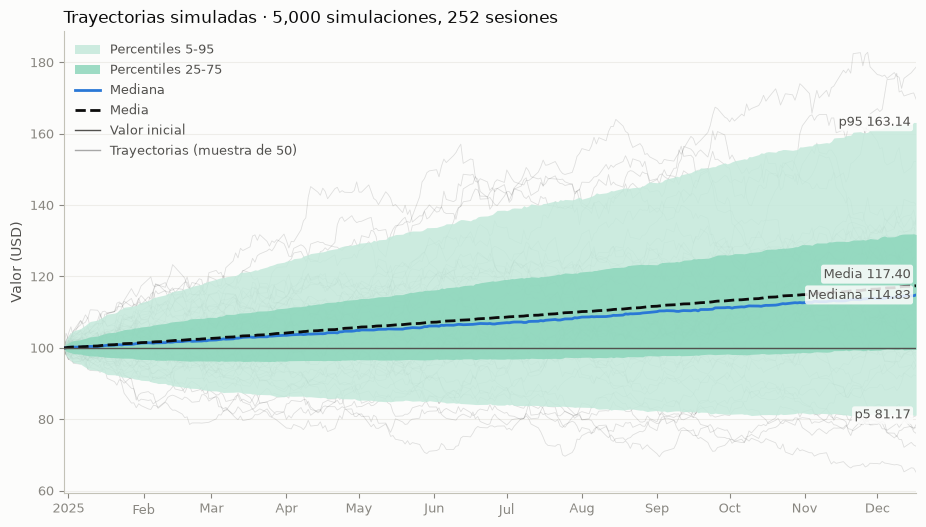

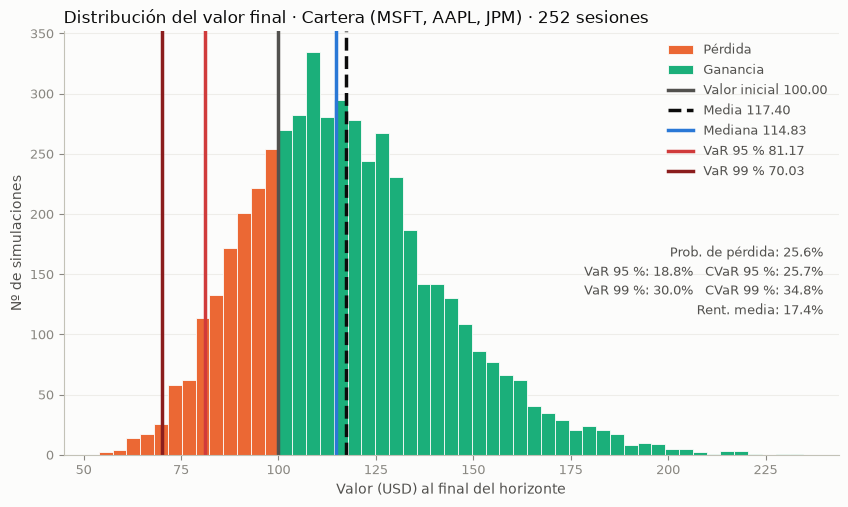

In [5]:
simulacion = MonteCarlo(cartera, n_simulaciones=5000, semilla=42, guardar_graficos=False)
simulacion.guardar_graficos(carpeta=CARPETA_SALIDA / "montecarlo")
resultado = simulacion.resumen()
print(f"Valor inicial:            {resultado['valor_inicial']:.2f}")
print(f"Valor final mediano:      {resultado['valor_final_mediano']:.2f}")
print(f"Probabilidad de pérdida:  {resultado['probabilidad_perdida']:.1%}")
print(f"VaR 95 %:                 {resultado['var_95']:.1%}")
print(f"CVaR 95 %:                {resultado['cvar_95']:.1%}")
print(f"Gráficos guardados en: {CARPETA_SALIDA / 'montecarlo'}")
simulacion.graficar()
plt.show()
plt.close("all")


## 4. Informe y gráficos de la cartera

Genera el informe Markdown, guarda los seis gráficos del informe y los muestra en el notebook.


Informe Markdown: outputs\informe.md
# Informe de cartera

## Información general

- **Número de activos:** 3
- **Periodo disponible:** 2022-01-03 a 2024-12-30
- **Observaciones:** 752
- **Moneda de referencia:** USD
- **Último rebalanceo explícito:** 2022-01-03
  - MSFT: 35.00%
  - AAPL: 35.00%
  - JPM: 30.00%
- **Valor final de 100 iniciales:** 143.16

### Composición por activo

| Activo | Peso actual | Rentabilidad histórica | Volatilidad anualizada | Contribución acumulada |
| --- | ---: | ---: | ---: | ---: |
| MSFT | 31.83% | 30.20% | 27.59% | 13.88% |
| AAPL | 34.43% | 40.83% | 27.11% | 10.68% |
| JPM | 33.74% | 60.98% | 25.01% | 18.60% |

## Rentabilidad

- **Rentabilidad acumulada:** 43.16%
- **CAGR:** 12.77%
- **Rentabilidad media diaria:** 0.057%
- **Mejor día:** 2022-11-10 (7.09%)
- **Peor día:** 2022-09-13 (-5.08%)
- **Mejor mes:** 2023-11 (11.96%)
- **Peor mes:** 2022-09 (-10.61%)

## Riesgo

- **Volatilidad anualizada:** 21.49%
- **Drawdown máximo:** 29.99%
- **Sharpe a

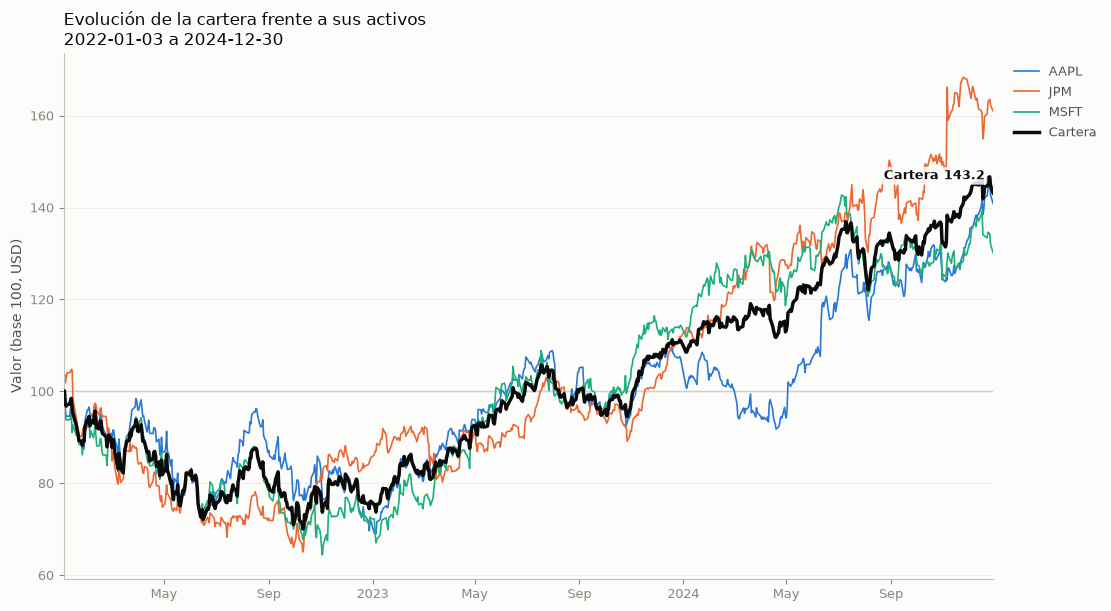

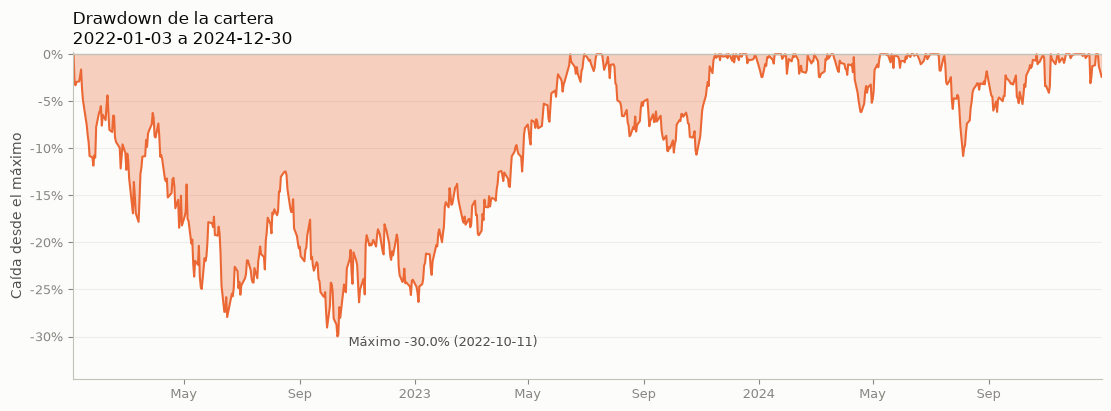

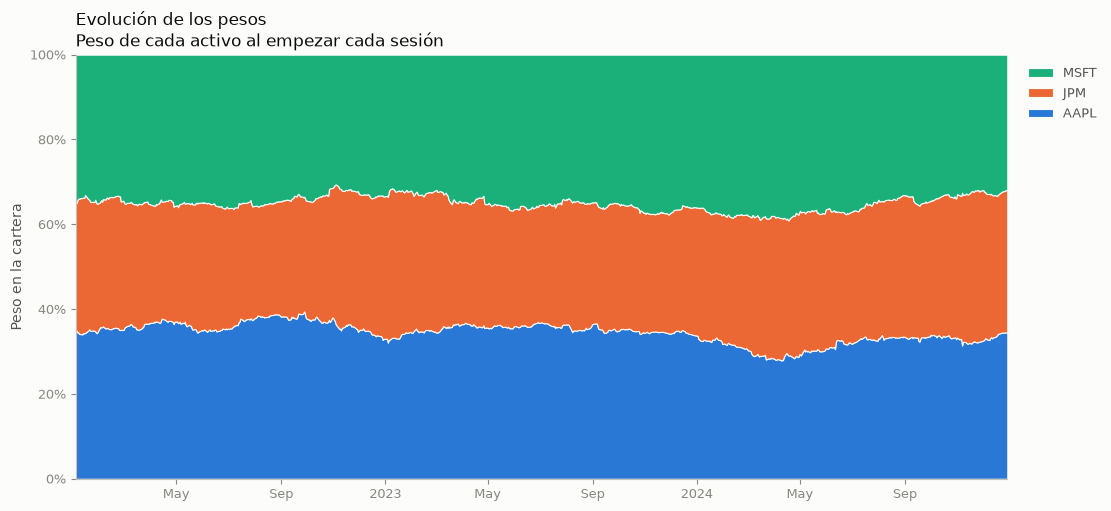

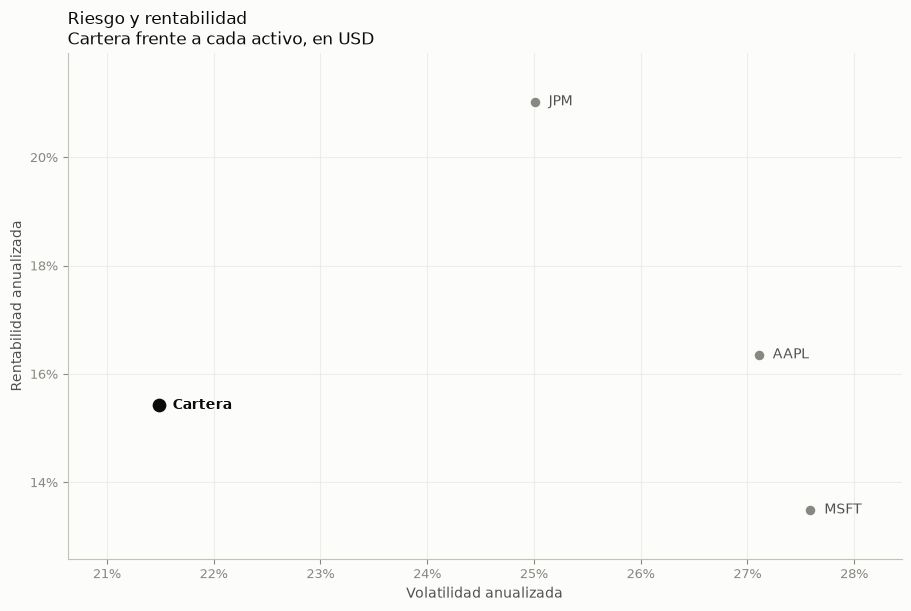

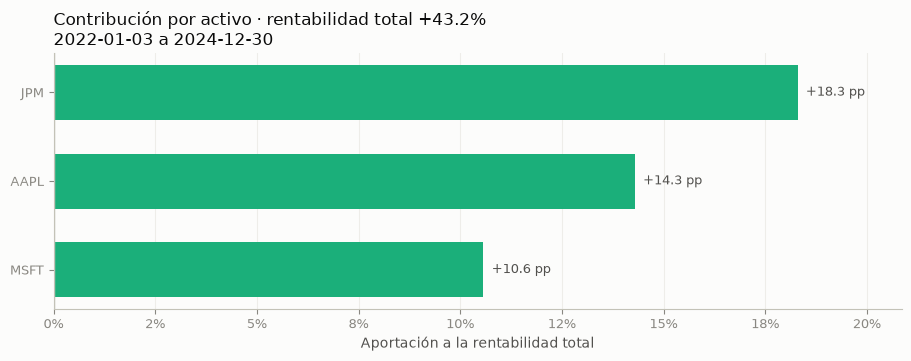

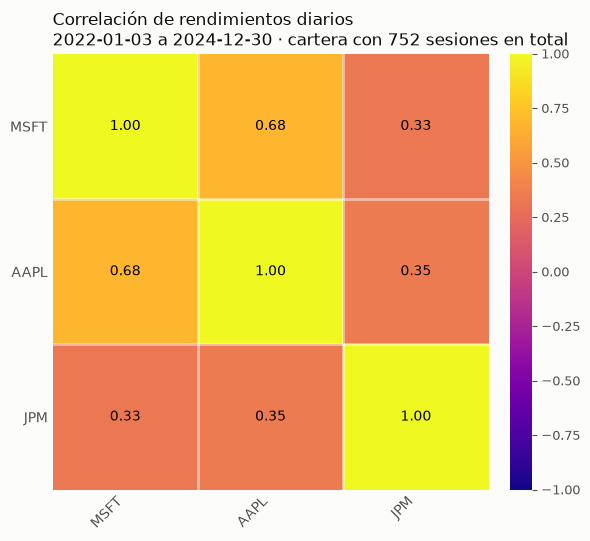

Demo terminada. Todos los resultados están en outputs/


In [7]:
informe = cartera.report(tasa_libre_riesgo=tipo_libre_riesgo)
ruta_informe = CARPETA_SALIDA / "informe.md"
ruta_informe.write_text(informe, encoding="utf-8")
print(f"Informe Markdown: {ruta_informe}")
print(informe)

cartera.plots_report(mostrar=True, carpeta=CARPETA_SALIDA / "graficos")
plt.show()
plt.close("all")
print(f"Demo terminada. Todos los resultados están en {CARPETA_SALIDA}/")
